# 01 — Problem Framing

## Pregunta de negocio
_(se cierra tras el diagnóstico de la Etapa 02)_

## Hipótesis candidatas
| # | Pregunta | H0 | H1 |
|---|---|---|---|
| A | ¿Las intros se han acortado con el tiempo? | La longitud de la intro no cambia entre épocas | La intro es más corta en las épocas recientes |
| B | ¿Hubo una "guerra del volumen" en los #1? | El loudness medio no varía por década | El loudness aumenta por década |
| C | ¿Más compositores implican mejor canción? | El nº de compositores no se asocia con la calificación de los jueces | Se asocia positivamente |
| D | ¿El "sonido" predice las semanas en el #1? | Las features de audio no mejoran la predicción frente a un baseline | Sí la mejoran |

**Criterio de elección:** la que tenga datos suficientes y limpios, efecto interpretable y una conclusión útil para una persona no técnica.

## Resultados esperados y supuestos
- Esperado: _(pendiente)_
- Supuestos: los #1 son una población completa (no una muestra); las features de Spotify están medidas de forma homogénea entre épocas; las calificaciones de los jueces son comparables entre canciones.

## Sesgos y limitaciones conocidos de antemano
- **Sesgo de selección:** solo hay canciones que llegaron al #1; no hay grupo de comparación.
- **Dependencia temporal:** las observaciones no son independientes entre épocas.
- **Subjetividad:** solo tres jueces.
- **Dimensionalidad:** n ≈ 1,150 con ~100 columnas → riesgo de falsos positivos por comparaciones múltiples.

## Criterios de éxito (definidos ANTES de ver resultados)
1. Efecto práctico relevante (tamaño de efecto por encima de un umbral razonable) y no solo p < 0.05.
2. Intervalo de confianza al 95% que excluya el valor nulo.
3. Conclusión estable en al menos 2 de 3 chequeos de robustez.
4. Si hay modelo: supera al baseline con margen mayor que su incertidumbre en validación cruzada.

In [53]:
import pandas as pd
import numpy as np

file_path = "../data/raw/Billboard_Hot_100_Number_Ones_Database.xlsx"
raw = pd.read_excel(file_path, sheet_name="Data", na_values=["Cannot Locate"])
df = raw.copy()   # `raw` queda intacto como evidencia; trabajamos sobre `df`

print(raw.shape)
raw["Date"].dtype, raw["Date"].head(3).tolist()

(1177, 105)


(dtype('<M8[ns]'),
 [Timestamp('1958-08-04 00:00:00'),
  Timestamp('1958-08-18 00:00:00'),
  Timestamp('1958-08-25 00:00:00')])

In [54]:
## Etapa 02, paso A: ingestión y diagnóstico

In [55]:
def diagnose(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_missing": df.isna().sum(),
        "pct_missing": (df.isna().mean() * 100).round(1),
        "n_unique": df.nunique(),
        "example": df.apply(lambda c: str(c.dropna().iloc[0])[:30] if c.notna().any() else None),
    }).sort_values("pct_missing", ascending=False)

diag = diagnose(raw)
print(raw.dtypes.astype(str).value_counts())
diag.head(25)

int64             62
object            26
float64           16
datetime64[ns]     1
Name: count, dtype: int64


,dtype,n_missing,pct_missing,n_unique,example
Featured in a Then Contemporary Play,object,1175,99.8,2,"Hello, Dolly"
Talent Contestant,object,1166,99.1,4,American Idol
Double A Side,object,1165,99.0,12,Something
Featured in a then Contemporary T.V. Show,object,1152,97.9,19,Larwence Welk Show
Sound Effects,object,1113,94.6,40,Hammer
Featured in a Then Contemporary Film,object,1073,91.2,92,A Summer Place
Featured Artists,object,988,83.9,174,Fran Lori (Vocals)
U.S. Artwork,object,424,36.0,33,Artist Photograph
Discogs Style,object,94,8.0,371,Rock & Roll
CDR Genre,object,88,7.5,32,Pop;Rock


In [56]:
## Celda 3: duplicados
keys = ["Song", "Artist", "Date"]
print("filas duplicadas completas:", raw.duplicated().sum())
print("duplicados por (Song, Artist, Date):", raw.duplicated(subset=keys).sum())
print("misma canción+artista en fechas distintas:", raw.duplicated(subset=["Song", "Artist"]).sum())

filas duplicadas completas: 0
duplicados por (Song, Artist, Date): 0
misma canción+artista en fechas distintas: 0


In [57]:
## Celda 4: valores inconsistentes (texto donde debería haber número, binarias fuera de {0,1})
obj = raw.select_dtypes("object").columns
as_num = {c: pd.to_numeric(raw[c], errors="coerce") for c in obj}
mixed = {c: raw.loc[as_num[c].isna() & raw[c].notna(), c].unique()[:5]
         for c in obj if as_num[c].notna().mean() > 0.8}   # mayoría numérica, con "basura" texto
print("columnas casi numéricas con valores de texto:", mixed)

num = raw.select_dtypes("number")
binary_like = [c for c in num if set(num[c].dropna().unique()) <= {0, 1, 0.0, 1.0}]
print("columnas binarias detectadas:", len(binary_like))
num.describe().T[["min", "max", "mean"]].head(30)

columnas casi numéricas con valores de texto: {}
columnas binarias detectadas: 54


,min,max,mean
Weeks at Number One,1.0,19.000000,2.937978
Non-Consecutive,0.0,1.000000,0.085811
Rating 1,1.0,10.000000,5.983857
Rating 2,1.0,10.000000,5.969414
Rating 3,1.0,10.000000,6.438403
Overall Rating,1.0,10.000000,6.130558
Divisiveness,0.0,5.333333,1.553101
Artist Structure,0.0,2.500000,0.781223
Multiple Lead Vocalists,0.0,1.000000,0.247239
Group Named After Non-Lead Singer,0.0,1.000000,0.016992


In [103]:
CRITICAL = ["Song", "Artist", "Date", "Weeks at Number One", "Rating 1", "Rating 2", "Rating 3",
            "Overall Rating", "Divisiveness", "BPM", "Energy", "Danceability", "Happiness",
            "Loudness (dB)", "Acousticness", "Length (Sec)", "Intro Length (Sec)",
            "Instrumental Length(Sec)", "Songwriters", "Producers", "Song Structure", "Lyrics"]
print("columnas críticas ausentes:", [c for c in CRITICAL if c not in raw.columns])
print("Date ordenada:", raw["Date"].is_monotonic_increasing, "|", raw["Date"].min().date(), "→", raw["Date"].max().date())

columnas críticas ausentes: []
Date ordenada: False | 1958-08-04 → 2025-01-11


In [105]:
r = raw[["Rating 1", "Rating 2", "Rating 3"]]
pairwise = ((r["Rating 1"] - r["Rating 2"]).abs() + (r["Rating 1"] - r["Rating 3"]).abs()
            + (r["Rating 2"] - r["Rating 3"]).abs()) / 3
spotify = raw[["Energy", "Danceability", "Happiness", "Acousticness"]]

checks = {
    "Overall Rating ≠ media de los 3 jueces":      (raw["Overall Rating"] - r.mean(axis=1)).abs() > 0.01,
    "Divisiveness ≠ distancia media por pares":    (raw["Divisiveness"] - pairwise).abs() > 0.01,
    "Intro más larga que la canción":              raw["Intro Length (Sec)"] > raw["Length (Sec)"],
    "Parte instrumental más larga que la canción": raw["Instrumental Length(Sec)"] > raw["Length (Sec)"],
    "Semanas en el #1 < 1":                        raw["Weeks at Number One"] < 1,
    "BPM fuera de [40, 220]":                      raw["BPM"].notna() & ~raw["BPM"].between(40, 220),
    "Métricas Spotify fuera de [0, 100]":          (spotify < 0).any(axis=1) | (spotify > 100).any(axis=1),
    "Loudness > 0 dB":                             raw["Loudness (dB)"] > 0,
    "Edad del líder < 15":                         raw["Front Person Age"] < 15,
}
report = pd.Series({k: int(v.sum()) for k, v in checks.items()}, name="violaciones")
report

Overall Rating ≠ media de los 3 jueces         0
Divisiveness ≠ distancia media por pares       0
Intro más larga que la canción                 0
Parte instrumental más larga que la canción    0
Semanas en el #1 < 1                           0
BPM fuera de [40, 220]                         1
Métricas Spotify fuera de [0, 100]             0
Loudness > 0 dB                                0
Edad del líder < 15                            9
Name: violaciones, dtype: int64

In [60]:
cols = ["Song", "Artist", "Date", "BPM", "Front Person Age", "Length (Sec)"]
raw.loc[checks["BPM fuera de [40, 220]"] | checks["Edad del líder < 15"], cols]

,Song,Artist,Date,BPM,Front Person Age,Length (Sec)
95,Fingertips Pt. 2,Stevie Wonder,1963-08-10,138.0,13.0,190
227,I Want You Back,The Jackson 5,1970-01-31,98.0,11.0,180
232,ABC,The Jackson 5,1970-04-25,94.0,11.0,175
236,The Love You Save,The Jackson 5,1970-06-27,114.0,11.0,180
243,I'll Be There,The Jackson 5,1970-10-17,93.0,12.0,238
259,Go Away Little Girl,Donny Osmond,1971-09-11,108.0,13.0,149
280,Ben,Michael Jackson,1972-10-14,136.0,14.0,167
546,Against All Odds (Take a Look at Me Now),Phil Collins,1984-04-21,16.0,33.0,206
767,Jump,Kris Kross,1992-04-25,102.0,12.5,193
815,MMMBop,Hanson,1997-05-24,105.0,14.0,238


In [61]:
df = raw.copy()
df["bpm_suspect"] = df["BPM"] < 40
df.loc[df["bpm_suspect"], "BPM"] = np.nan

AUDIO = ["BPM", "Energy", "Danceability", "Happiness", "Loudness (dB)", "Acousticness"]
df["Year"] = df["Date"].dt.year
df["Decade"] = (df["Year"] // 10 * 10).astype(int)
print(df.groupby("Decade").size())
print(df[AUDIO].isna().sum())
print("filas completas en audio:", df[AUDIO].dropna().shape[0])

Decade
1950     23
1960    203
1970    253
1980    231
1990    140
2000    129
2010    116
2020     82
dtype: int64
BPM              3
Energy           2
Danceability     2
Happiness        2
Loudness (dB)    2
Acousticness     2
dtype: int64
filas completas en audio: 1174


## Pregunta
¿Los #1 del Hot 100 se han vuelto más parecidos entre sí en su sonido a lo largo del tiempo?

## Definiciones (fijadas antes de ver los resultados)
- Unidad de análisis: canción (semana en que debutó en el #1), sin ponderar por semanas.
- "Sonido": 6 variables de audio (BPM, Energy, Danceability, Happiness, Loudness, Acousticness), estandarizadas.
- "Homogeneidad": dispersión del sonido dentro de cada época.
  - Métrica principal: distancia media al centroide de su época (multivariada).
  - Secundarias: desviación estándar de cada variable por separado.
- Épocas: décadas (agrupando las primeras si el n es bajo).

## Hipótesis
- H0: la dispersión del sonido es la misma en todas las épocas.
- H1: la dispersión es menor en las épocas recientes (dirección esperada, fijada de antemano).

## Qué espero y por qué
Que la dispersión baje: la producción moderna, la radio y el streaming premian fórmulas probadas.
Pero no es obvio: también pudo ampliarse con la llegada del hip-hop y la música latina.

## Supuestos
- Las métricas de Spotify son comparables entre épocas (incluso para grabaciones antiguas).
- Cada #1 es una observación independiente dentro de su época.

## Sesgos y limitaciones
- Solo hay canciones que llegaron al #1 (sin grupo de comparación).
- El número de #1 por año cambia: antes rotaban rápido, ahora duran más.
- Las métricas de Spotify son modelos, no mediciones; hay errores como el BPM de 16.
- Comparaciones múltiples: 6 variables × varias épocas.

## Criterios de éxito (antes de ver resultados)
1. Tamaño de efecto relevante (razón de desviaciones estándar o diferencia en distancia al centroide) con IC 95% que excluya "sin cambio".
2. Conclusión estable en al menos 2 de 3 chequeos de robustez (otra definición de época, sin el BPM sospechoso, remuestreo bootstrap).
3. Significancia después de corregir por comparaciones múltiples (Holm).

In [69]:
bins   = [1957, 1969, 1979, 1989, 1999, 2009, 2019, 2025]
labels = ["1958-69", "1970s", "1980s", "1990s", "2000s", "2010s", "2020-25"]

df["Epoch"]  = pd.cut(df["Year"], bins=bins, labels=labels)
df["Genre1"] = df["CDR Genre"].str.split(";").str[0]          # género principal (nulo si no hay)

KEEP = ["Song", "Artist", "Date", "Year", "Decade", "Epoch", "Weeks at Number One",
        "Genre1", "bpm_suspect"] + AUDIO
analysis = df[KEEP].copy()

# validaciones del dataset final
assert analysis["Epoch"].notna().all(), "hay canciones sin época"
assert analysis[["Song", "Artist", "Date"]].duplicated().sum() == 0
assert analysis[AUDIO].dropna().shape[0] >= 1170
#assert analysis["Date"].is_monotonic_increasing

analysis.to_csv("../data/processed/analysis_dataset.csv", index=False)
analysis["Epoch"].value_counts().sort_index()

Epoch
1958-69    226
1970s      253
1980s      231
1990s      140
2000s      129
2010s      116
2020-25     82
Name: count, dtype: int64

 ## Etapa 03: Exploratory & Statistical Analysis

In [73]:
## Celda 1: estandarización y distancia al centroide de su época
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

A = analysis.dropna(subset=AUDIO).copy()
print(len(A), "complete-case songs")

Z = (A[AUDIO] - A[AUDIO].mean()) / A[AUDIO].std()          # global z-scores
centroid = Z.groupby(A["Epoch"], observed=True).transform("mean")
A["dist_centroid"] = np.sqrt(((Z - centroid) ** 2).sum(axis=1))

1174 complete-case songs


In [75]:
## Celda 2: estadísticos descriptivos por época (menor distancia = más homogéneo)
g = A.groupby("Epoch", observed=True)
desc = pd.DataFrame({"n": g.size(),
                     "mean_dist": g["dist_centroid"].mean(),
                     "median_dist": g["dist_centroid"].median()}).round(2)
pd.concat([desc, g[AUDIO].std().round(1).add_suffix("_sd")], axis=1)

,n,mean_dist,median_dist,BPM_sd,Energy_sd,Danceability_sd,Happiness_sd,Loudness (dB)_sd,Acousticness_sd
Epoch,,,,,,,,,
1958-69,226,2.28,2.13,24.1,20.5,14.7,22.6,3.2,28.5
1970s,253,2.22,2.13,21.9,18.7,15.4,23.8,3.1,27.2
1980s,229,2.28,2.17,23.7,20.7,14.0,26.9,3.5,22.0
1990s,139,2.20,2.11,22.7,19.1,14.2,27.4,2.3,25.2
2000s,129,1.89,1.82,26.6,13.9,13.9,21.8,2.0,15.7
2010s,116,1.87,1.80,23.2,16.9,11.7,21.6,1.8,23.4
2020-25,82,2.09,2.01,32.7,13.8,13.4,22.1,1.8,22.8


                skew  excess_kurtosis  shapiro_p
BPM            0.436            0.028        0.0
Energy        -0.253           -0.482        0.0
Danceability  -0.350           -0.151        0.0
Happiness     -0.398           -0.962        0.0
Loudness (dB) -0.608            0.396        0.0
Acousticness   0.740           -0.719        0.0


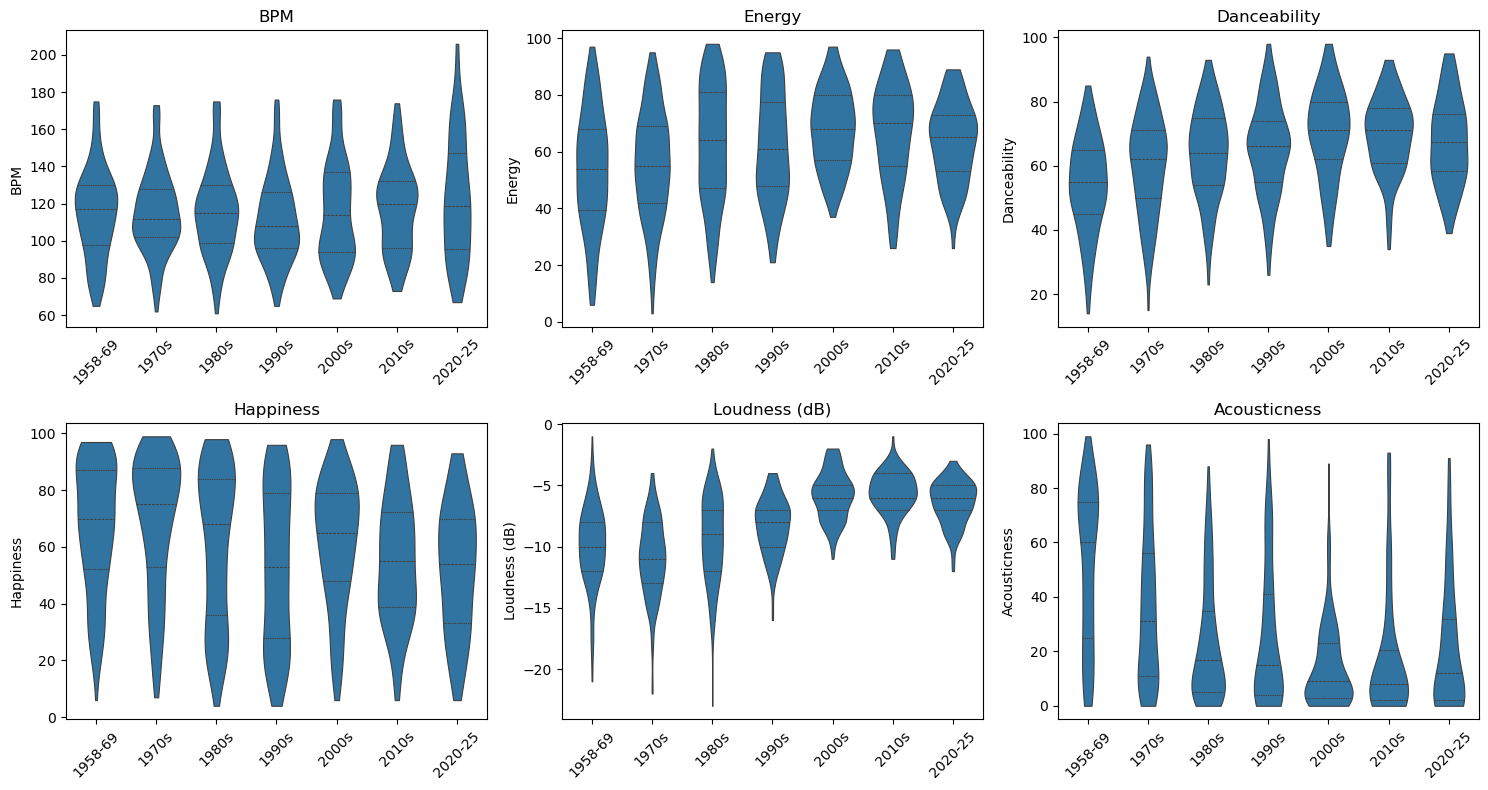

In [77]:
## Celda 3: distribución de cada variable. Con n ≈ 1,100 el test de Shapiro rechaza casi todo, así que mira asimetría y curtosis, no solo el p-valor.
shape = pd.DataFrame({"skew": A[AUDIO].skew(), "excess_kurtosis": A[AUDIO].kurt(),
                      "shapiro_p": {c: stats.shapiro(A[c])[1] for c in AUDIO}}).round(3)
print(shape)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), AUDIO):
    sns.violinplot(data=A, x="Epoch", y=c, inner="quartile", cut=0, ax=ax, linewidth=.8)
    ax.set_title(c); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

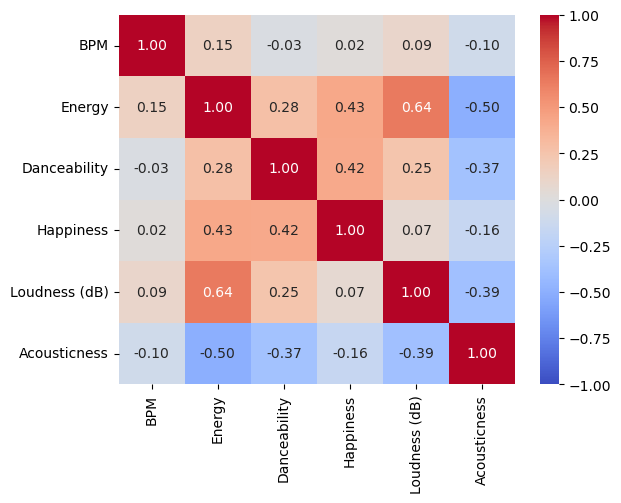

In [79]:
## Celda 4: correlaciones. Si Energy y Loudness correlacionan fuerte, la distancia euclidiana cuenta dos veces el mismo “factor” y pesa de más.
corr = A[AUDIO].corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.show()

In [85]:
corr

,BPM,Energy,Danceability,Happiness,Loudness (dB),Acousticness
BPM,1.000000,0.147066,-0.027269,0.019639,0.094494,-0.101111
Energy,0.147066,1.000000,0.276645,0.426944,0.643454,-0.503605
Danceability,-0.027269,0.276645,1.000000,0.416701,0.245515,-0.368292
Happiness,0.019639,0.426944,0.416701,1.000000,0.067351,-0.163825
Loudness (dB),0.094494,0.643454,0.245515,0.067351,1.000000,-0.389841
Acousticness,-0.101111,-0.503605,-0.368292,-0.163825,-0.389841,1.000000


In [81]:
## Celda 5: posibles confusores (variables que cambian con la época y podrían explicar un cambio en la dispersión sin que sea “homogeneización”)
A["artist_songs_in_epoch"] = A.groupby(["Epoch", "Artist"], observed=True)["Song"].transform("size")
g = A.groupby("Epoch", observed=True)
conf = pd.DataFrame({
    "songs_per_year": g.size() / (g["Year"].max() - g["Year"].min() + 1),
    "mean_weeks_at_1": g["Weeks at Number One"].mean(),
    "pct_songs_by_repeat_artists": (A["artist_songs_in_epoch"] > 1).groupby(A["Epoch"], observed=True).mean(),
}).round(2)
print(conf)

top = A["Genre1"].value_counts().head(6).index
A["GenreGroup"] = A["Genre1"].where(A["Genre1"].isin(top), "Other").fillna("Unknown")
pd.crosstab(A["Epoch"], A["GenreGroup"], normalize="index").round(2)

         songs_per_year  mean_weeks_at_1  pct_songs_by_repeat_artists
Epoch                                                                
1958-69           18.83             2.63                         0.45
1970s             25.30             2.07                         0.51
1980s             22.90             2.27                         0.54
1990s             13.90             3.74                         0.40
2000s             12.90             4.03                         0.28
2010s             11.60             4.57                         0.34
2020-25           13.67             3.01                         0.37


GenreGroup,Electronic/Dance,Folk/Country,Funk/Soul,Hip Hop,Other,Pop,Rock
Epoch,,,,,,,
1958-69,0.00,0.07,0.08,0.00,0.03,0.43,0.38
1970s,0.01,0.03,0.37,0.00,0.01,0.30,0.28
1980s,0.14,0.00,0.12,0.00,0.01,0.34,0.39
1990s,0.06,0.00,0.32,0.14,0.01,0.32,0.14
2000s,0.12,0.01,0.26,0.33,0.03,0.17,0.08
2010s,0.28,0.00,0.09,0.22,0.09,0.30,0.02
2020-25,0.00,0.00,0.00,0.00,1.00,0.00,0.00


Qué estamos buscando con cada celda
Celda 2: el primer vistazo a la hipótesis. ¿Baja mean_dist hacia las épocas recientes? ¿Y las desviaciones por variable?
Celda 3: decide qué pruebas usamos. Si hay colas pesadas o asimetría, Brown-Forsythe (basada en la mediana) es la elección correcta frente a Levene, y lo justificas con evidencia.
Celda 4: decide si hacemos la comparación multivariada también con PCA o con distancia de Mahalanobis, como chequeo de sensibilidad.
Celda 5: si cambian mucho la mezcla de géneros, la rotación de #1 o la repetición de artistas entre épocas, hay que controlarlo en la Etapa 04 o declararlo como limitación.

In [87]:
print(analysis.groupby("Epoch", observed=True)["Genre1"].apply(lambda s: s.isna().mean()).round(2))

Epoch
1958-69    0.00
1970s      0.00
1980s      0.00
1990s      0.00
2000s      0.00
2010s      0.05
2020-25    1.00
Name: Genre1, dtype: float64


In [89]:
top = A["Genre1"].value_counts().head(6).index
g1 = A["Genre1"].fillna("Unknown")
A["GenreGroup"] = g1.where(g1.isin(list(top) + ["Unknown"]), "Other")
pd.crosstab(A["Epoch"], A["GenreGroup"], normalize="index").round(2)

GenreGroup,Electronic/Dance,Folk/Country,Funk/Soul,Hip Hop,Other,Pop,Rock,Unknown
Epoch,,,,,,,,
1958-69,0.00,0.07,0.08,0.00,0.03,0.43,0.38,0.00
1970s,0.01,0.03,0.37,0.00,0.01,0.30,0.28,0.00
1980s,0.14,0.00,0.12,0.00,0.01,0.34,0.39,0.00
1990s,0.06,0.00,0.32,0.14,0.01,0.32,0.14,0.00
2000s,0.12,0.01,0.26,0.33,0.03,0.17,0.08,0.00
2010s,0.28,0.00,0.09,0.22,0.04,0.30,0.02,0.05
2020-25,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00


In [91]:
# (a) distancia sin BPM  (b) distancia tipo Mahalanobis  (c) BPM plegado a [70,140)
Z5 = Z.drop(columns="BPM")
c5 = Z5.groupby(A["Epoch"], observed=True).transform("mean")
A["dist_noBPM"] = np.sqrt(((Z5 - c5) ** 2).sum(axis=1))

cz = Z.groupby(A["Epoch"], observed=True).transform("mean")
d = (Z - cz).values
A["dist_mahal"] = np.sqrt(np.einsum("ij,jk,ik->i", d, np.linalg.inv(np.cov(Z.T)), d))

A["BPM_folded"] = A["BPM"] / 2 ** np.floor(np.log2(A["BPM"] / 70))

ge = A.groupby("Epoch", observed=True)
cmp = ge[["dist_centroid", "dist_noBPM", "dist_mahal"]].mean().round(2)
cmp["BPM_sd"] = ge["BPM"].std().round(1)
cmp["BPM_folded_sd"] = ge["BPM_folded"].std().round(1)
cmp

,dist_centroid,dist_noBPM,dist_mahal,BPM_sd,BPM_folded_sd
Epoch,,,,,
1958-69,2.28,2.07,2.34,24.1,20.5
1970s,2.22,2.03,2.23,21.9,18.5
1980s,2.28,2.07,2.28,23.7,19.0
1990s,2.20,1.98,2.20,22.7,18.0
2000s,1.89,1.55,2.01,26.6,20.2
2010s,1.87,1.62,1.98,23.2,20.7
2020-25,2.09,1.63,2.16,32.7,19.8


In [99]:
df["Genre1"] = df["Discogs Genre"].str.split(",").str[0]
# vuelve a correr la creación de `analysis` y de `A`, y luego:
print(analysis.groupby("Epoch", observed=True)["Genre1"].apply(lambda s: s.isna().mean()).round(2))
analysis["Genre1"].value_counts().head(10)

Epoch
1958-69    0.00
1970s      0.00
1980s      0.00
1990s      0.00
2000s      0.00
2010s      0.05
2020-25    1.00
Name: Genre1, dtype: float64


Genre1
Pop                 355
Rock                281
Funk/Soul           228
Electronic/Dance     91
Hip Hop              88
Folk/Country         25
Reggae               10
Jazz                  5
Latin                 3
Polka                 1
Name: count, dtype: int64

In [101]:
def dispersion(data, cols, mahal=False):
    Zx = (data[cols] - data[cols].mean()) / data[cols].std()
    d = (Zx - Zx.groupby(data["Epoch"], observed=True).transform("mean")).values
    if mahal:
        return np.sqrt(np.einsum("ij,jk,ik->i", d, np.linalg.inv(np.cov(Zx.T)), d))
    return np.sqrt((d ** 2).sum(axis=1))

A["BPM_f"] = A["BPM_folded"]
five  = [c for c in AUDIO if c != "BPM"]
fold6 = ["BPM_f"] + five
A["m1_prereg"]      = dispersion(A, AUDIO)
A["m2_noBPM"]       = dispersion(A, five)
A["m3_foldedBPM"]   = dispersion(A, fold6)
A["m4_mahal_fold"]  = dispersion(A, fold6, mahal=True)

A.groupby("Epoch", observed=True)[["m1_prereg", "m2_noBPM", "m3_foldedBPM", "m4_mahal_fold"]].mean().round(2)

,m1_prereg,m2_noBPM,m3_foldedBPM,m4_mahal_fold
Epoch,,,,
1958-69,2.28,2.07,2.33,2.37
1970s,2.22,2.03,2.24,2.25
1980s,2.28,2.07,2.29,2.28
1990s,2.20,1.98,2.19,2.19
2000s,1.89,1.55,1.86,2.01
2010s,1.87,1.62,1.93,2.05
2020-25,2.09,1.63,1.91,1.99
